# Real NVP

In [1]:
# Import required packages
import torch
import numpy as np

import normflows_ours as nf


from matplotlib import pyplot as plt
from tqdm import tqdm

In [2]:
from normflows_ours.distributions.base import BaseDistribution


class Uniform(BaseDistribution):
    """
    Multivariate uniform distribution
    """

    def __init__(self, shape, low=-1.0, high=1.0):
        """Constructor

        Args:
          shape: Tuple with shape of data, if int shape has one dimension
          low: Lower bound of uniform distribution
          high: Upper bound of uniform distribution
        """
        super().__init__()
        if isinstance(shape, int):
            shape = (shape,)
        if isinstance(shape, list):
            shape = tuple(shape)
        self.shape = shape
        self.d = np.prod(shape)
        self.register_buffer("low", torch.tensor(low).expand(self.shape))
        self.register_buffer("high", torch.tensor(high).expand(self.shape))

    def forward(self, num_samples=1, context=None):
        eps = torch.rand(
            (num_samples,) + self.shape, dtype=self.low.dtype, device=self.low.device
        )
        z = self.low + (self.high - self.low) * eps

        log_p = -self.d * torch.log(self.high[0] - self.low[0] ) * torch.ones(num_samples, device=self.low.device)

        return z, log_p

    def log_prob(self, z, context=None):
        log_p = -self.d * torch.log(self.high[0] - self.low[0]) * torch.ones(z.shape[0], device=z.device)
        out_range = torch.logical_or(z < self.low, z > self.high)
        ind_inf = torch.any(torch.reshape(out_range, (z.shape[0], -1)), dim=-1)
        log_p[ind_inf] = -torch.inf
        return log_p
    
    

In [3]:
class Uniform2(BaseDistribution):
    """
    Distribution of a 1D random variable with some entries having a uniform and
    others a Gaussian distribution
    """

    def __init__(self, ndim, ind, scale=None):
        """Constructor

        Args:
          ndim: Int, number of dimensions
          ind: Iterable, indices of uniformly distributed entries
          scale: Iterable, standard deviation of Gaussian or width of uniform distribution
        """
        super().__init__()
        self.ndim = ndim
        if isinstance(ind, int):
            ind = [ind]

        # Set up indices and permutations
        self.ndim = ndim
        if torch.is_tensor(ind):
            self.register_buffer("ind", torch._cast_Long(ind))
        else:
            self.register_buffer("ind", torch.tensor(ind, dtype=torch.long))

        ind_ = []
        for i in range(self.ndim):
            if not i in self.ind:
                ind_ += [i]
        self.register_buffer("ind_", torch.tensor(ind_, dtype=torch.long))

        perm_ = torch.cat((self.ind, self.ind_))
        inv_perm_ = torch.zeros_like(perm_)
        for i in range(self.ndim):
            inv_perm_[perm_[i]] = i
        self.register_buffer("inv_perm", inv_perm_)

        if scale is None:
            self.register_buffer("scale", torch.ones(self.ndim))
        else:
            self.register_buffer("scale", scale)

    def forward(self, num_samples=1, context=None):
        z = self.sample(num_samples)
        return z, self.log_prob(z)

    def sample(self, num_samples=1, context=None):
        eps_u = (
            torch.rand(
                (num_samples, len(self.ind)),
                dtype=self.scale.dtype,
                device=self.scale.device,
            )
        )
        eps_g = torch.randn(
            (num_samples, len(self.ind_)),
            dtype=self.scale.dtype,
            device=self.scale.device,
        )
        z = torch.cat((eps_u, eps_g), -1)
        z = z[..., self.inv_perm]
        return self.scale * z

    def log_prob(self, z, context=None):
        in_support = ((z >= 0) & (z <= 1)).all(dim=1)
        log_p_u = torch.broadcast_to(-torch.log(self.scale[self.ind]), (len(z), -1))
        log_p_g = (
            -0.5 * np.log(2 * np.pi)
            - torch.log(self.scale[self.ind_])
            - 0.5 * torch.pow(z[..., self.ind_] / self.scale[self.ind_], 2)
        )
        log_p_u[~in_support] = float('-inf')
        return torch.sum(log_p_u, -1) + torch.sum(log_p_g, -1)

In [4]:
from normflows_ours.distributions.prior import PriorDistribution

class TargetDistribution:
    """Custom target distribution defined over [0,1]^2."""
    
    def __init__(self, device, dist_type="gradient"):
        self.device = device
        self.dist_type = dist_type
        print(f"Using target distribution: {dist_type}")
    
    def log_prob(self, x):
        """Log probability of custom distribution over [0,1]^2"""
        # x has shape (B, seq_length, latent_dim) - model format
        # Extract the float from each sequence position: (B, 2)
        x_user = x  # Shape: (B, 2) - one float per position
        
        # Clamp to [0,1] for safety
        x_clamped = torch.clamp(x_user, 0.0, 1.0)
        
        if self.dist_type == "gradient":
            # Linear gradient: higher density in top-right, lower in bottom-left
            # log_prob = a * (x1 + x2) + b
            gradient_strength = 2.0
            log_prob = gradient_strength * (x_clamped[:, 0] + x_clamped[:, 1])
            # Normalize (subtract log normalizing constant)
            log_prob = log_prob - np.log(4.0 * (np.exp(2*gradient_strength) - 1) / gradient_strength**2)
            
        elif self.dist_type == "bimodal":
            # Two peaks: one at (0.2, 0.8) and one at (0.8, 0.2)
            peak1 = torch.tensor([0.2, 0.8], device=self.device)
            peak2 = torch.tensor([0.8, 0.2], device=self.device)
            std = 0.15
            
            # Distance to each peak
            dist1 = torch.sum((x_clamped - peak1)**2, dim=1)
            dist2 = torch.sum((x_clamped - peak2)**2, dim=1)
            
            # Log probability as mixture of two Gaussians
            log_prob1 = -0.5 * dist1 / (std**2) - np.log(2 * np.pi * std**2)
            log_prob2 = -0.5 * dist2 / (std**2) - np.log(2 * np.pi * std**2)
            
            # Log-sum-exp for mixture
            max_log_prob = torch.max(log_prob1, log_prob2)
            log_prob = max_log_prob + torch.log(
                torch.exp(log_prob1 - max_log_prob) + torch.exp(log_prob2 - max_log_prob)
            ) + np.log(0.5)  # Equal mixture weights
            
        elif self.dist_type == "corners":
            # Higher density in corners (0,1) and (1,0), lower in (0,0) and (1,1)
            # Use a function like: -|x1 - x2|
            diff = torch.abs(x_clamped[:, 0] - x_clamped[:, 1])
            log_prob = -2.0 * diff
            # Add normalizing constant
            log_prob = log_prob - np.log(0.5)  # Approximate normalization
            
        elif self.dist_type == "ring":
            # Ring/donut shape centered at (0.5, 0.5)
            center = torch.tensor([0.5, 0.5], device=self.device)
            distance = torch.sqrt(torch.sum((x_clamped - center)**2, dim=1))
            target_radius = 0.3
            ring_width = 0.1
            
            # Gaussian ring
            log_prob = -0.5 * ((distance - target_radius) / ring_width)**2
            log_prob = log_prob - np.log(np.sqrt(2 * np.pi) * ring_width)
            
        elif self.dist_type == "checkerboard":
            # Checkerboard pattern
            x1_bin = torch.floor(x_clamped[:, 0] * 4)  # 4x4 grid
            x2_bin = torch.floor(x_clamped[:, 1] * 4)
            is_high = ((x1_bin + x2_bin) % 2 == 0).float()
            
            # Higher log prob for "white" squares, lower for "black"
            log_prob = torch.where(is_high > 0.5, 
                                 torch.tensor(1.0, device=self.device),
                                 torch.tensor(-1.0, device=self.device))
            # Normalize
            log_prob = log_prob - np.log((np.exp(1.0) + np.exp(-1.0)) / 2)
            
        else:
            raise ValueError(f"Unknown distribution type: {self.dist_type}")
        
        return log_prob
    
    def _format_for_log_prob(self, x_2d):
        """Convert (N, 2) format to model format (N, 2, 1)"""
        return x_2d.unsqueeze(-1)
    
    def sample(self, num_samples):
        """Generate samples from the target distribution (for visualization)"""
        if self.dist_type == "gradient":
            # Rejection sampling for gradient distribution
            samples = []
            while len(samples) < num_samples:
                candidates = torch.rand(num_samples * 2, 2, device=self.device)
                log_probs = self.log_prob(self._format_for_log_prob(candidates))
                probs = torch.exp(log_probs)
                accept_prob = torch.rand(len(candidates), device=self.device)
                accepted = candidates[accept_prob < probs / probs.max()]
                if len(accepted) > 0:
                    samples.append(accepted)
            return torch.cat(samples)[:num_samples]
        
        elif self.dist_type == "bimodal":
            # Direct sampling from mixture
            n1 = num_samples // 2
            n2 = num_samples - n1
            
            samples1 = torch.normal(0.2, 0.15, (n1, 1), device=self.device).repeat(1, 2)
            samples1[:, 1] = torch.normal(0.8, 0.15, (n1,), device=self.device)
            
            samples2 = torch.normal(0.8, 0.15, (n2, 1), device=self.device).repeat(1, 2)
            samples2[:, 1] = torch.normal(0.2, 0.15, (n2,), device=self.device)
            
            samples = torch.cat([samples1, samples2])
            return torch.clamp(samples, 0, 1)
        
        else:
            # Use rejection sampling for other distributions
            samples = []
            max_attempts = num_samples * 10
            attempts = 0
            while len(samples) < num_samples and attempts < max_attempts:
                candidates = torch.rand(min(num_samples * 2, max_attempts - attempts), 2, device=self.device)
                log_probs = self.log_prob(self._format_for_log_prob(candidates))
                probs = torch.exp(log_probs - log_probs.max())  # Normalize
                accept_prob = torch.rand(len(candidates), device=self.device)
                accepted = candidates[accept_prob < probs]
                if len(accepted) > 0:
                    samples.append(accepted)
                attempts += len(candidates)
            
            if len(samples) > 0:
                all_samples = torch.cat(samples)
                return all_samples[:num_samples]
            else:
                # Fallback to uniform if sampling fails
                return torch.rand(num_samples, 2, device=self.device)

Using device: cuda
Using target distribution: checkerboard


/tmp/ipykernel_122766/3879153437.py:73: UserWarning: Use of index_put_ on expanded tensors is deprecated. Please clone() the tensor before performing this operation. This also applies to advanced indexing e.g. tensor[indices] = tensor (Triggered internally at ../aten/src/ATen/native/TensorAdvancedIndexing.cpp:792.)
  log_p_u[~in_support] = float('-inf')
/tmp/ipykernel_122766/3879153437.py:73: UserWarning: Use of masked_fill_ on expanded tensors is deprecated. Please clone() the tensor before performing this operation. This also applies to advanced indexing e.g. tensor[mask] = scalar (Triggered internally at ../aten/src/ATen/native/cuda/Indexing.cu:1597.)
  log_p_u[~in_support] = float('-inf')


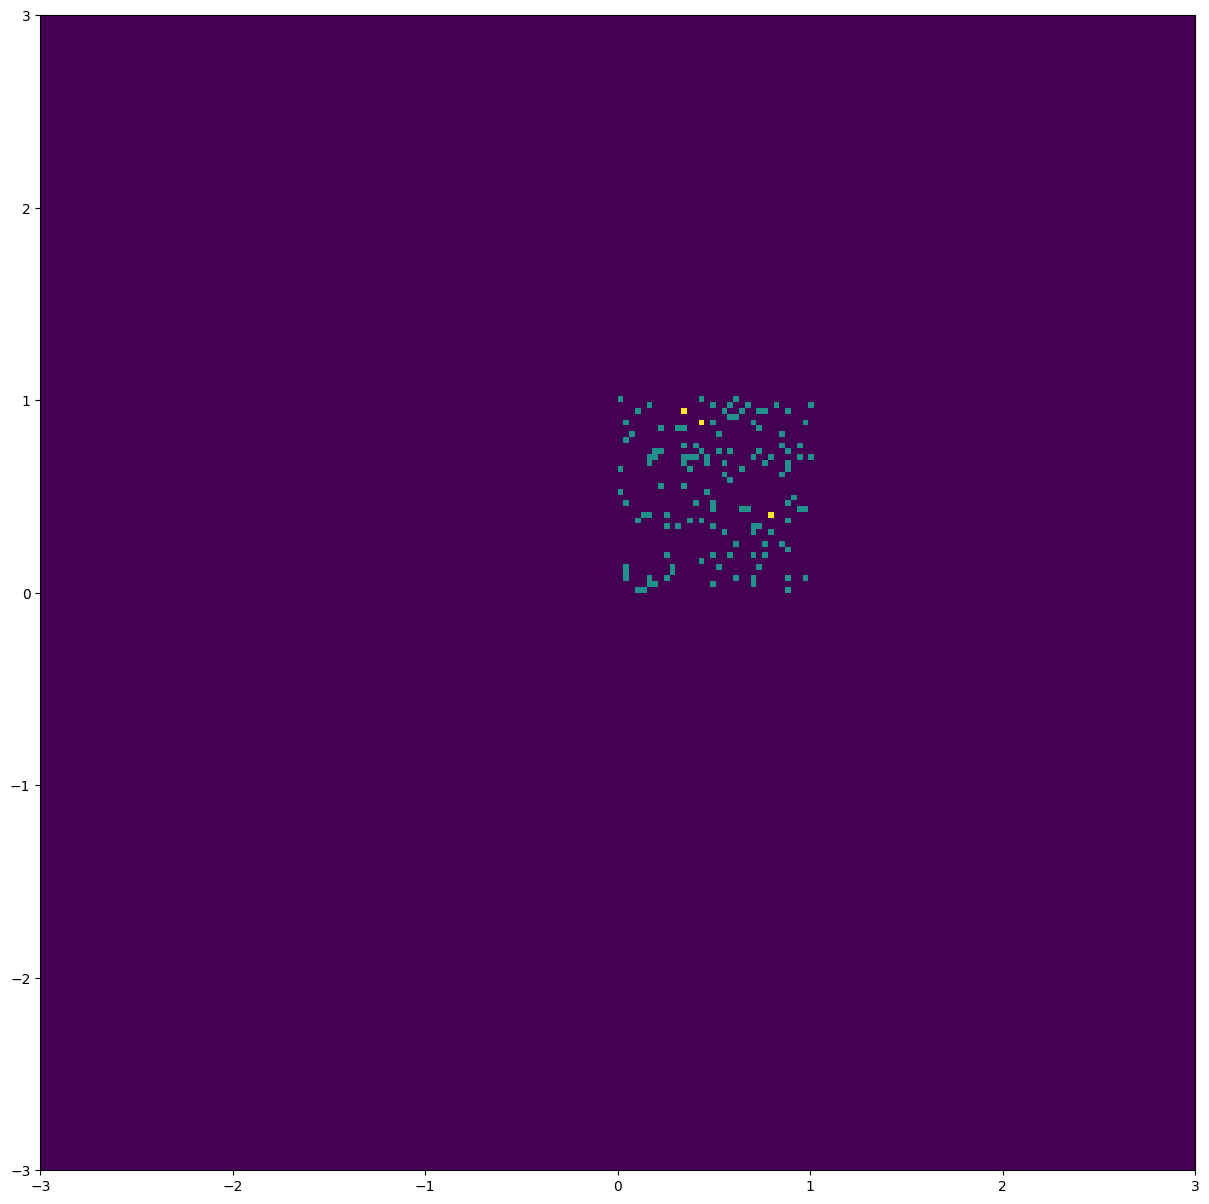

In [5]:
# Set up model
# Define flows
K = 4
torch.manual_seed(0)

latent_size = 2
b = torch.Tensor([1 if i % 2 == 0 else 0 for i in range(latent_size)])


flows = []
hidden_units = 128
hidden_layers = 2
if 1:
    for i in range(K):
        flows += [nf.flows.AutoregressiveRationalQuadraticSpline(latent_size, hidden_layers, hidden_units, tails=None, tail_bound=1.0)]
        flows += [nf.flows.LULinearPermute(latent_size)]
else:
    for i in range(K):
        flows += [nf.flows.CoupledRationalQuadraticSpline(latent_size, hidden_layers, hidden_units, tails=None, tail_bound=1.0)]
        flows += [nf.flows.Permute(2, mode='swap')]

# Move model on GPU if available
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')
print(f"Using device: {device}")
# Set target and q0
#target = SmileyOur(loc=2.0, scale=0.02)
target = TargetDistribution(device, dist_type="checkerboard")
#q0 = Uniform(2, 0.0, 1.0)
#q0 = nf.distributions.DiagGaussian(2, trainable=False)
#q0 = nf.distributions.UniformGaussian(2, ind=[0, 1])
q0 = Uniform2(2, ind=[0, 1])

# Construct flow model
nfm = nf.NormalizingFlow(q0=q0, flows=flows, p=target)

nfm = nfm.to(device)


nfm = nfm.double()

# Initialize ActNorm
z, _ = nfm.sample(num_samples=2 ** 7)
z_np = z.to('cpu').data.numpy()
plt.figure(figsize=(15, 15))
plt.hist2d(z_np[:, 0].flatten(), z_np[:, 1].flatten(), (200, 200), range=[[-3, 3], [-3, 3]])
plt.gca().set_aspect('equal', 'box')
plt.show()

/home/mishok43/miniconda3/envs/r_evaluator/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/tmp/ipykernel_122766/3879153437.py:73: UserWarning: Use of index_put_ on expanded tensors is deprecated. Please clone() the tensor before performing this operation. This also applies to advanced indexing e.g. tensor[indices] = tensor (Triggered internally at ../aten/src/ATen/native/TensorAdvancedIndexing.cpp:792.)
  log_p_u[~in_support] = float('-inf')
/tmp/ipykernel_122766/3879153437.py:73: UserWarning: Use of masked_fill_ on expanded tensors is deprecated. Please clone() the tensor before performing this operation. This also applies to advanced indexing e.g. tensor[mask] = scalar (Triggered internally at ../aten/src/ATen/native/cuda/Indexing.cu:

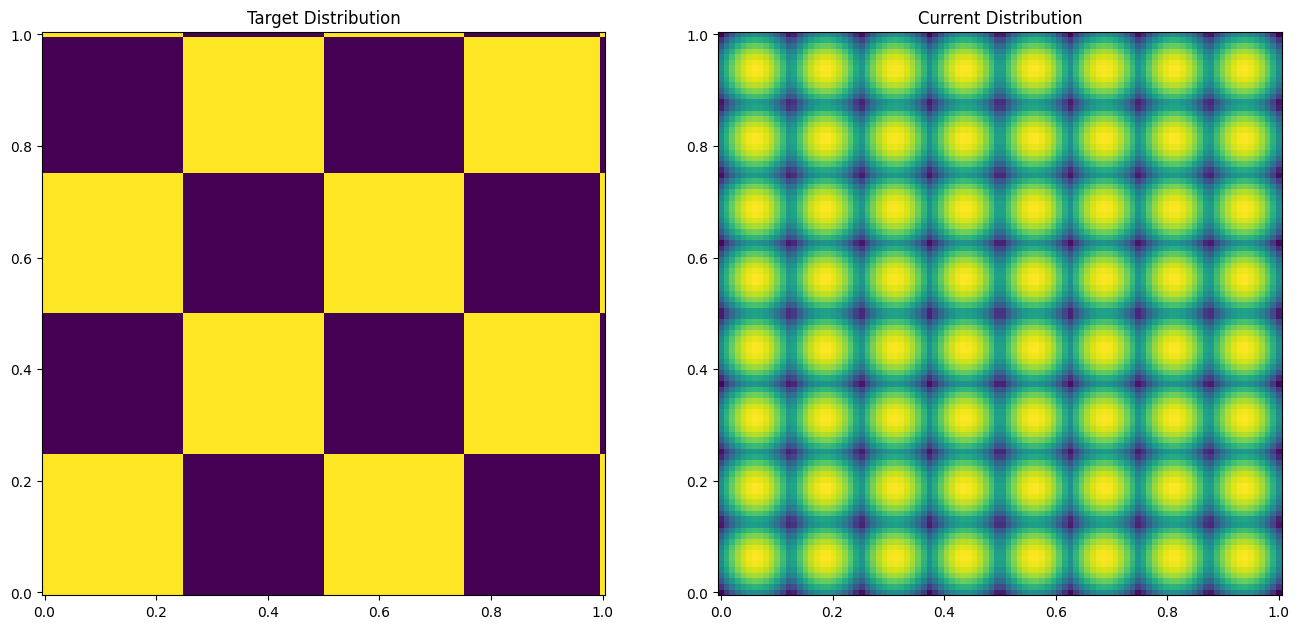

In [6]:
# Plot target distribution and initial posterior distribution
grid_size = 100
xx, yy = torch.meshgrid(torch.linspace(0, 1, grid_size), torch.linspace(0, 1, grid_size))

zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
zz = zz.double().to(device)

# Get target distribution
log_prob = target.log_prob(zz).to('cpu').view(*xx.shape)
prob_target = torch.exp(log_prob)

# Get current posterior distribution
log_prob = nfm.log_prob(zz).to('cpu').view(*xx.shape)
prob = torch.exp(log_prob)
prob[torch.isnan(prob)] = 0

# Plot both distributions side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

ax1.pcolormesh(xx, yy, prob_target.data.numpy())
ax1.set_aspect('equal', 'box')
ax1.set_title('Target Distribution')

ax2.pcolormesh(xx, yy, prob.data.numpy())
ax2.set_aspect('equal', 'box')
ax2.set_title('Current Distribution')

plt.show()

In [ ]:
# Train model
max_iter = 1000
num_samples = 5000
anneal_iter = 10000
annealing = False
show_iter = 25



optimizer = torch.optim.Adam(nfm.parameters(), lr=1e-3, weight_decay=1e-6)
for it in tqdm(range(max_iter)):
    optimizer.zero_grad()

    # nfm - our trainable neural distributio that we use to sample render space. x = render space state (uniforms). log_pdf_q_sample - log probability of our trainable distribution for sampled render space 
    with torch.no_grad():
        x, log_pdf_q_sample = nfm.sample(num_samples=num_samples)

    # log_pdf_q - log probability of our trainable distribution for sampled render space 
    log_pdf_q = nfm.log_prob(x)
    # log_p_pdf - log probability of our target distribution for sampled render space. it should be render_time at this particular state of render space DIVIDED by the total averaged time . we get it from performance measurement 
    log_p_pdf = nfm.p.log_prob(x).detach()


    #weight = -torch.exp(log_p_pdf-log_pdf_q_sample)
    weight = -torch.exp(log_p_pdf)/torch.exp(log_pdf_q_sample) # we can pre-apply exp, as our render system uses exp(log_pdf) everywhere
    loss = torch.mean(weight*log_pdf_q)

    print(f"Iteration {it} loss: {loss}")


    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()
        #torch.nn.utils.clip_grad_norm_(nfm.parameters(), 50)
        optimizer.step()
    else:
        print(f"NaN or Inf loss at iteration {it}")
    
    
    # Plot learned posterior
    if (it + 1) % show_iter == 0 or show_iter == 1:
        print(loss)
        log_prob = nfm.log_prob(zz).to('cpu').view(*xx.shape)
        prob = torch.exp(log_prob)

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
        ax1.pcolormesh(xx, yy, prob_target.data.numpy())
        ax1.set_aspect('equal', 'box')
        ax1.set_title('Target Distribution')

        ax2.pcolormesh(xx, yy, prob.data.numpy())
        ax2.set_aspect('equal', 'box')
        ax2.set_title('Current Distribution')
        plt.show() 

plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.legend()
plt.show()

In [ ]:
# Plot learned posterior distribution
log_prob = nfm.log_prob(zz).to('cpu').view(*xx.shape)
prob = torch.exp(log_prob)
prob[torch.isnan(prob)] = 0

plt.figure(figsize=(15, 15))
plt.pcolormesh(xx, yy, prob.data.numpy())
plt.contour(xx, yy, prob_target.data.numpy(), cmap=plt.get_cmap('cool'), linewidths=2)
plt.gca().set_aspect('equal', 'box')
plt.show()